<a href="https://colab.research.google.com/github/Metba09/gpuweb/blob/main/remotion_to_glb_hunyuan3d(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Remotion (zip) → assets 2D → Hunyuan3D → GLB (zip)

Pipeline en 8 étapes :

1. **Configuration** (paramètres en formulaire)
2. **Installation** de Hunyuan3D-2 et des dépendances (avec `transformers` 4.x épinglé)
3. **Import** du projet Remotion packagé en `.zip`
4. **Extraction des assets 2D** (images, SVG, images clés de vidéos)
5. **Téléchargement du modèle** depuis Hugging Face (vérifié)
6. **Chargement** du modèle Hunyuan3D
7. **Modélisation 3D** de chaque asset (détourage → maillage → GLB)
8. **Validation et export** des GLB dans un `.zip`

> Si l'étape 2 affiche « Redémarrage du runtime », c'est normal (une bibliothèque déjà chargée
> a changé de version) : relancez simplement l'étape 1 puis l'étape 2.

**Prérequis :** Exécution → Modifier le type d'exécution → **GPU (T4 ou mieux)**.
Exécutez ensuite les cellules dans l'ordre.

> Licence : *Tencent Hunyuan 3D 2.0 Community License*. Elle ne s'applique **pas** dans l'UE,
> le Royaume-Uni et la Corée du Sud, et l'usage des modèles **et de leurs sorties** hors du
> « Territoire » n'est pas autorisé. Au-delà de 1 M d'utilisateurs actifs mensuels, une licence
> spécifique de Tencent est requise. Vérifiez qu'elle convient à votre usage.
>
> Mémoire GPU : ≈ 6 Go pour la forme seule, ≈ 16 Go avec texture (selon le README du dépôt).

In [ ]:
#@title 1. Configuration { display-mode: "form" }
import os, sys, json, shutil, subprocess, zipfile, hashlib, time, re, gc, struct, traceback, importlib
from pathlib import Path

# --- Source du zip Remotion ---
SOURCE = "upload"      #@param ["upload", "drive", "path"]
ZIP_PATH = ""          #@param {type:"string"}

# --- Modèle ---
MODEL_NAME = "Hunyuan3D-2mini"  #@param ["Hunyuan3D-2mini", "Hunyuan3D-2"]
TEXTURE = False        #@param {type:"boolean"}

# --- Extraction des assets 2D ---
MIN_SIDE = 128         #@param {type:"integer"}
MAX_ASSETS = 12        #@param {type:"integer"}
EXTRACT_VIDEO_FRAMES = False  #@param {type:"boolean"}
VIDEO_FRAME_SECOND = 1.0      #@param {type:"number"}

# --- Génération 3D ---
STEPS = 30             #@param {type:"integer"}
GUIDANCE = 5.0         #@param {type:"number"}
OCTREE_RESOLUTION = 256  #@param [192, 256, 320, 380]
SEED = 2025            #@param {type:"integer"}
SIMPLIFY_FACES = 40000  #@param {type:"integer"}

# --- Sortie ---
OUT_ZIP_NAME = "assets_glb.zip"  #@param {type:"string"}

# --- Hugging Face (facultatif : jeton en lecture, sinon secret Colab « HF_TOKEN ») ---
HF_TOKEN = ""          #@param {type:"string"}

# --- Dossiers de travail ---
ROOT = Path("/content") if Path("/content").exists() else Path.cwd() / "colab_work"
ROOT.mkdir(parents=True, exist_ok=True)
REPO_URL = "https://github.com/Tencent-Hunyuan/Hunyuan3D-2.git"
REPO_DIR = ROOT / "Hunyuan3D-2"
PROJECT_DIR = ROOT / "remotion_project"
WORK_DIR = ROOT / "pipeline_out"
FRAMES_DIR = WORK_DIR / "video_frames"
PREP_DIR = WORK_DIR / "prepared_2d"
GLB_DIR = WORK_DIR / "glb"
HF_MODELS_DIR = ROOT / "hy3dgen_models"
for d in (WORK_DIR, FRAMES_DIR, PREP_DIR, GLB_DIR, HF_MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Hunyuan3D cherche d'abord ses poids dans <HY3DGEN_MODELS>/<repo_id>/<sous-dossier> :
# l'étape 5 les y télécharge explicitement depuis Hugging Face.
os.environ["HY3DGEN_MODELS"] = str(HF_MODELS_DIR)


def sh(cmd, cwd=None, check=True, tail=12):
    """Exécute une commande shell et affiche la fin de la sortie."""
    print("$", cmd)
    p = subprocess.run(cmd, shell=True, cwd=cwd, text=True,
                       stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    lines = (p.stdout or "").strip().splitlines()
    if lines:
        print("\n".join(lines[-tail:]))
    if check and p.returncode != 0:
        raise RuntimeError(f"Commande en échec (code {p.returncode}) : {cmd}")
    return p


try:
    import torch
    if torch.cuda.is_available():
        print("GPU :", torch.cuda.get_device_name(0))
    else:
        print("⚠️ Aucun GPU détecté : activez un GPU dans le type d'exécution avant l'étape 6.")
except ImportError:
    print("torch non importable pour l'instant (sera disponible après l'installation).")

print("Dossier de travail :", ROOT)

GPU : NVIDIA A100-SXM4-80GB
Dossier de travail : /content


In [ ]:
#@title 2. Installation de Hunyuan3D-2 { display-mode: "form" }
if not (REPO_DIR / "setup.py").exists():
    sh(f"git clone --depth 1 {REPO_URL} {REPO_DIR}")

# On n'utilise PAS requirements.txt / setup.py du dépôt : ils tirent gradio, fastapi,
# uvicorn et opencv-python (inutiles ici, lourds, sources de conflits sur Colab).
# Liste ciblée = imports réellement nécessaires à hy3dgen.shapegen + rembg + ce notebook.
# torch / torchvision / numpy sont ceux de Colab (non réinstallés).
import importlib.util
from importlib import metadata

# COMPATIBILITÉ : les poids Hunyuan3D utilisent les anciens noms de couches de Dinov2
# (attention.attention.query, mlp.weights_in…). transformers >= 5.18 les a renommés
# (q_proj, gate_proj…) => « Unexpected key(s) in state_dict ». On reste donc en 4.x.
TRANSFORMERS_SPEC = "transformers>=4.48.0,<5"
BASE_DEPS = ("diffusers accelerate safetensors omegaconf einops pymeshlab scikit-image scipy "
             "pyyaml tqdm huggingface_hub trimesh pygltflib rembg onnxruntime cairosvg")
# Pillow n'est volontairement pas listé (évite de le monter en v13 et de casser gradio sur Colab).
# OpenCV : on réutilise celui de Colab s'il existe, pour ne pas installer deux variantes.
if importlib.util.find_spec("cv2") is None:
    BASE_DEPS += " opencv-python-headless"
sh(f'{sys.executable} -m pip install -q "{TRANSFORMERS_SPEC}" {BASE_DEPS}')

if TEXTURE:
    # Dépendances supplémentaires du module de texture (texgen)
    sh(f"{sys.executable} -m pip install -q xatlas pybind11 ninja")

importlib.invalidate_caches()


def stale_modules(names=("transformers", "huggingface_hub", "tokenizers", "diffusers")):
    """Modules déjà chargés dans ce noyau dont la version sur disque a changé."""
    out = []
    for n in names:
        m = sys.modules.get(n)
        if m is None:
            continue
        try:
            installed = metadata.version(n.replace("_", "-"))
        except metadata.PackageNotFoundError:
            continue
        loaded = getattr(m, "__version__", installed)
        if loaded != installed:
            out.append((n, loaded, installed))
    return out


def restart_runtime():
    print("🔄 Redémarrage du runtime… Une fois reconnecté, relancez l'étape 1 puis l'étape 2.")
    os.kill(os.getpid(), 9)


stale = stale_modules()
if stale:
    for n, a, b in stale:
        print(f"⚠️ {n} : version chargée {a} ≠ version installée {b}")
    restart_runtime()

from packaging.version import Version
import transformers
TF_VERSION = transformers.__version__
if not (Version("4.48.0") <= Version(TF_VERSION) < Version("5.0")):
    raise RuntimeError(f"transformers {TF_VERSION} chargé : version 4.x requise (>=4.48). "
                       "Menu Exécution → Redémarrer la session, puis relancez les étapes 1 et 2.")
print("transformers", TF_VERSION)

# Le dépôt est utilisé directement via sys.path (hy3dgen est un paquet pur Python).
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))
try:
    import hy3dgen  # noqa: F401
except Exception as e:
    raise RuntimeError(f"hy3dgen introuvable dans {REPO_DIR} : {e}")

print("✅ Installation terminée.")

$ git clone --depth 1 https://github.com/Tencent-Hunyuan/Hunyuan3D-2.git /content/Hunyuan3D-2
Cloning into '/content/Hunyuan3D-2'...
$ /usr/bin/python3 -m pip install -q "transformers>=4.48.0,<5" diffusers accelerate safetensors omegaconf einops pymeshlab scikit-image scipy pyyaml tqdm huggingface_hub trimesh pygltflib rembg onnxruntime cairosvg
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
transformers 4.57.6
✅ Installation terminée.


In [ ]:
#@title 3. Import du projet Remotion (.zip) { display-mode: "form" }
MAX_UNZIPPED_BYTES = 4 * 1024 ** 3  # garde-fou contre les zip bombs (4 Go)


def get_zip_path():
    if SOURCE == "upload" and not ZIP_PATH:
        from google.colab import files
        uploaded = files.upload()
        zips = [n for n in uploaded if n.lower().endswith(".zip")]
        if not zips:
            raise RuntimeError("Aucun fichier .zip reçu.")
        return Path.cwd() / zips[0]
    if SOURCE == "drive":
        from google.colab import drive
        drive.mount("/content/drive")
    if not ZIP_PATH:
        raise RuntimeError("Renseignez ZIP_PATH (SOURCE = 'drive' ou 'path').")
    p = Path(ZIP_PATH).expanduser()
    if not p.is_file():
        raise FileNotFoundError(f"Zip introuvable : {p}")
    if p.suffix.lower() != ".zip":
        raise ValueError(f"Ce n'est pas un .zip : {p.name}")
    return p


def safe_extract(zip_path, dest):
    """Extrait le zip en refusant les chemins hors du dossier cible (zip-slip)."""
    dest = Path(dest).resolve()
    skip = ("node_modules/", "__MACOSX/", ".git/")
    with zipfile.ZipFile(zip_path) as zf:
        bad = zf.testzip()
        if bad:
            raise ValueError(f"Archive corrompue (fichier : {bad})")
        if sum(m.file_size for m in zf.infolist()) > MAX_UNZIPPED_BYTES:
            raise ValueError("Archive trop volumineuse une fois décompressée (> 4 Go)")
        members = []
        for m in zf.infolist():
            name = m.filename.replace("\\", "/")
            if any(("/" + name).find("/" + s) != -1 for s in skip):
                continue
            target = (dest / name).resolve()
            if target != dest and not str(target).startswith(str(dest) + os.sep):
                raise ValueError(f"Chemin suspect dans l'archive : {m.filename}")
            members.append(m)
        zf.extractall(dest, members=members)
    return len(members)


def find_project_root(base):
    """Repère le dossier du projet Remotion (package.json mentionnant remotion)."""
    best = None
    for dp, dn, fn in os.walk(base):
        dn[:] = [d for d in dn if d != "node_modules"]
        if "package.json" in fn:
            try:
                txt = (Path(dp) / "package.json").read_text(encoding="utf-8", errors="ignore")
            except OSError:
                continue
            if "remotion" in txt:
                return Path(dp)
            best = best or Path(dp)
    return best or Path(base)


def list_compositions(root):
    ids = set()
    pat = re.compile(r"<Composition[^>]*?\bid=[\"']([^\"']+)[\"']", re.S)
    for dp, dn, fn in os.walk(root):
        dn[:] = [d for d in dn if d != "node_modules"]
        for f in fn:
            if f.endswith((".tsx", ".ts", ".jsx", ".js")):
                try:
                    txt = (Path(dp) / f).read_text(encoding="utf-8", errors="ignore")
                except OSError:
                    continue
                ids.update(pat.findall(txt))
    return sorted(ids)


zip_path = get_zip_path()
if PROJECT_DIR.exists():
    shutil.rmtree(PROJECT_DIR)
PROJECT_DIR.mkdir(parents=True)
n = safe_extract(zip_path, PROJECT_DIR)
REMOTION_ROOT = find_project_root(PROJECT_DIR)
print(f"✅ {n} fichiers extraits depuis {zip_path.name}")
print("Racine du projet :", REMOTION_ROOT)
comps = list_compositions(REMOTION_ROOT)
print("Compositions détectées :", ", ".join(comps) if comps else "(aucune)")

Saving apstrim.zip to apstrim.zip
✅ 204 fichiers extraits depuis apstrim.zip
Racine du projet : /content/remotion_project
Compositions détectées : ApstrimSpot


✅ 12 asset(s) 2D retenu(s)
  - assets_01-images_s1_donor_nurse          562x319  [image]
  - assets_01-images_s3_donor_m              433x376  [image]
  - assets_01-images_s3_group4               509x263  [image]
  - assets_01-images_s1_heart_family         500x266  [image]
  - assets_01-images_s3_nurse                326x380  [image]
  - assets_01-images_s2_donor_red            373x315  [image]
  - assets_01-images_s3_donor_f              326x356  [image]
  - assets_01-images_s4_nurse                297x377  [image]
  - assets_01-images_s4_donor_arm            333x330  [image]
  - assets_01-images_s2_doctor               298x353  [image]
  - assets_01-images_s1_group5               422x220  [image]
  - assets_01-images_s2_nurse_bag            296x311  [image]


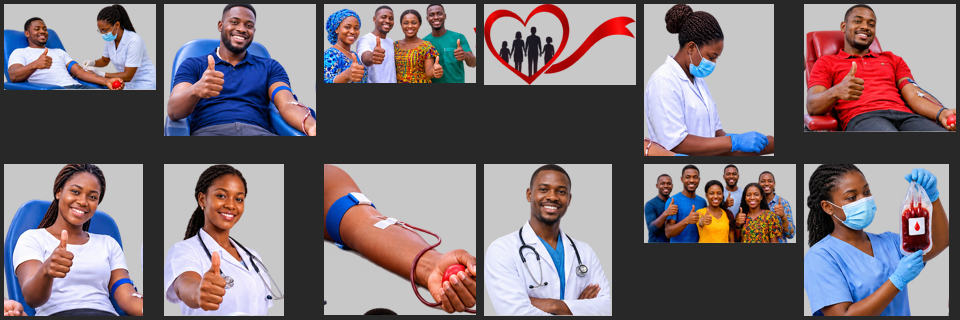

In [ ]:
#@title 4. Extraction des assets 2D { display-mode: "form" }
import io
import numpy as np
from PIL import Image

IMG_EXT = {".png", ".jpg", ".jpeg", ".webp", ".bmp", ".gif", ".svg"}
VID_EXT = {".mp4", ".mov", ".webm", ".mkv"}
SKIP_DIRS = {"node_modules", ".git", "out", "build", "dist", ".cache", "__MACOSX", ".next"}


def iter_files(root):
    for dp, dn, fn in os.walk(root):
        dn[:] = sorted(d for d in dn if d not in SKIP_DIRS)
        for f in sorted(fn):
            yield Path(dp) / f


def load_image(path):
    """Charge une image (SVG rasterisé) en RGBA."""
    path = Path(path)
    if path.suffix.lower() == ".svg":
        import cairosvg
        data = cairosvg.svg2png(url=str(path), output_width=1024)
        with Image.open(io.BytesIO(data)) as im:
            return im.convert("RGBA")
    with Image.open(path) as im:
        return im.convert("RGBA")


def extract_video_frame(video, out_png, second=1.0):
    cmd = ["ffmpeg", "-y", "-loglevel", "error", "-ss", str(second), "-i", str(video),
           "-frames:v", "1", str(out_png)]
    r = subprocess.run(cmd, capture_output=True, text=True)
    return r.returncode == 0 and Path(out_png).exists() and Path(out_png).stat().st_size > 0


def make_uid(rel, used):
    base = re.sub(r"[^A-Za-z0-9._-]+", "_", str(Path(rel).with_suffix(""))).strip("_") or "asset"
    uid, k = base, 1
    while uid in used:
        k += 1
        uid = f"{base}_{k}"
    used.add(uid)
    return uid


def scan_assets(root, min_side=128, max_assets=0, video_frames=False, frame_second=1.0):
    root = Path(root)
    records, seen, used = [], set(), set()
    for path in iter_files(root):
        ext = path.suffix.lower()
        rel = path.relative_to(root)
        src_path, kind = path, "image"
        if ext in VID_EXT:
            if not video_frames:
                continue
            uid_tmp = make_uid(rel, set())
            out_png = FRAMES_DIR / f"{uid_tmp}.png"
            if not extract_video_frame(path, out_png, frame_second):
                print("  ⚠️ image clé impossible :", rel)
                continue
            src_path, kind = out_png, "video_frame"
        elif ext not in IMG_EXT:
            continue
        try:
            img = load_image(src_path)
        except Exception as e:
            print(f"  ⚠️ illisible : {rel} ({type(e).__name__})")
            continue
        w, h = img.size
        if min(w, h) < min_side:
            continue
        thumb = img.resize((64, 64)).tobytes()
        digest = hashlib.sha1(thumb + f"{w}x{h}".encode()).hexdigest()
        if digest in seen:
            continue
        seen.add(digest)
        records.append({"id": make_uid(rel, used), "src": str(rel), "path": str(src_path),
                        "kind": kind, "width": w, "height": h})
    records.sort(key=lambda r: r["width"] * r["height"], reverse=True)
    if max_assets and max_assets > 0:
        records = records[:max_assets]
    return records


def make_contact_sheet(records, cols=6, cell=160):
    rows = max(1, (len(records) + cols - 1) // cols)
    sheet = Image.new("RGB", (cols * cell, rows * cell), (40, 40, 40))
    for i, r in enumerate(records):
        try:
            im = load_image(r["path"])
            im.thumbnail((cell - 8, cell - 8))
            bg = Image.new("RGBA", im.size, (200, 200, 200, 255))
            bg.alpha_composite(im)
            sheet.paste(bg.convert("RGB"), ((i % cols) * cell + 4, (i // cols) * cell + 4))
        except Exception:
            pass
    return sheet


ASSETS = scan_assets(REMOTION_ROOT, MIN_SIDE, MAX_ASSETS, EXTRACT_VIDEO_FRAMES, VIDEO_FRAME_SECOND)
(WORK_DIR / "assets_index.json").write_text(json.dumps(ASSETS, indent=2, ensure_ascii=False), encoding="utf-8")

print(f"✅ {len(ASSETS)} asset(s) 2D retenu(s)")
for r in ASSETS:
    print(f"  - {r['id']:<40} {r['width']}x{r['height']}  [{r['kind']}]")
if not ASSETS:
    print("⚠️ Aucun asset : baissez MIN_SIDE ou vérifiez le contenu de public/ et src/.")
else:
    try:
        from IPython.display import display
        display(make_contact_sheet(ASSETS))
    except Exception:
        pass

In [ ]:
#@title 5. Téléchargement du modèle depuis Hugging Face { display-mode: "form" }
from huggingface_hub import HfApi, hf_hub_download, snapshot_download

PRESETS = {
    "Hunyuan3D-2mini": ("tencent/Hunyuan3D-2mini", "hunyuan3d-dit-v2-mini"),
    "Hunyuan3D-2": ("tencent/Hunyuan3D-2", "hunyuan3d-dit-v2-0"),
}
TEXTURE_REPO = "tencent/Hunyuan3D-2"
TEXTURE_FOLDERS = ["hunyuan3d-delight-v2-0", "hunyuan3d-paint-v2-0-turbo"]
MIN_WEIGHTS_BYTES = 1_000_000


def get_hf_token():
    tok = (HF_TOKEN or "").strip() or os.environ.get("HF_TOKEN", "").strip()
    if not tok:
        try:
            from google.colab import userdata
            tok = (userdata.get("HF_TOKEN") or "").strip()
        except Exception:
            tok = ""
    return tok or None


def with_retries(fn, what, attempts=3):
    """Réessaie les erreurs réseau ; les erreurs d'accès (401/403) sont signalées tout de suite."""
    last = None
    for i in range(1, attempts + 1):
        try:
            return fn()
        except Exception as e:
            last = e
            msg = f"{type(e).__name__}: {e}"
            if any(k in msg for k in ("401", "403", "gated", "restricted", "Unauthorized")):
                raise RuntimeError(f"Accès refusé à Hugging Face pour {what} ({msg}). "
                                   "Renseignez HF_TOKEN (jeton en lecture) ou le secret Colab HF_TOKEN.") from e
            print(f"  ⚠️ {what} : tentative {i}/{attempts} échouée ({msg[:160]})")
            if i < attempts:
                time.sleep(2 ** i)
    raise RuntimeError(f"Téléchargement impossible : {what} ({type(last).__name__}: {last})") from last


def pick_weights(repo_files, subfolder):
    """Choisit les poids réellement présents dans le dépôt : fp16 de préférence."""
    inside = sorted(f for f in repo_files if f.startswith(subfolder + "/"))
    if f"{subfolder}/config.yaml" not in inside:
        raise FileNotFoundError(f"config.yaml absent de {subfolder}/ (contenu : {inside[:10]})")
    for fname, variant in (("model.fp16.safetensors", "fp16"), ("model.safetensors", None)):
        if f"{subfolder}/{fname}" in inside:
            return [f"{subfolder}/config.yaml", f"{subfolder}/{fname}"], variant
    raise FileNotFoundError(f"Aucun poids .safetensors dans {subfolder}/ (contenu : {inside[:10]})")


def verify_weights(path):
    """Taille plausible + en-tête safetensors lisible (détecte un téléchargement tronqué)."""
    path = Path(path)
    if not path.is_file() or path.stat().st_size < MIN_WEIGHTS_BYTES:
        raise RuntimeError(f"Fichier de poids absent ou trop petit : {path}")
    from safetensors import safe_open
    with safe_open(str(path), framework="np") as f:
        n_keys = len(list(f.keys()))
    if n_keys == 0:
        raise RuntimeError(f"Fichier safetensors vide : {path}")
    return n_keys


def download_shape_model(repo_id, subfolder, base_dir, token=None, api=None, download=None):
    api = api or HfApi(token=token)
    download = download or hf_hub_download
    repo_files = with_retries(lambda: api.list_repo_files(repo_id), f"liste des fichiers de {repo_id}")
    wanted, variant = pick_weights(repo_files, subfolder)
    local_dir = Path(base_dir) / repo_id
    local_dir.mkdir(parents=True, exist_ok=True)
    for fname in wanted:
        print(f"  ⬇️ {repo_id}/{fname}")
        with_retries(lambda f=fname: download(repo_id=repo_id, filename=f, local_dir=str(local_dir), token=token),
                     fname)
    weights = local_dir / wanted[1]
    n_keys = verify_weights(weights)
    return {"variant": variant, "weights": weights, "n_tensors": n_keys,
            "size_gb": weights.stat().st_size / 1e9}


def download_texture_models(base_dir, token=None, snapshot=None):
    snapshot = snapshot or snapshot_download
    local_dir = Path(base_dir) / TEXTURE_REPO
    local_dir.mkdir(parents=True, exist_ok=True)
    with_retries(lambda: snapshot(repo_id=TEXTURE_REPO, allow_patterns=[f"{d}/*" for d in TEXTURE_FOLDERS],
                                  local_dir=str(local_dir), token=token), "modèles de texture")
    for d in TEXTURE_FOLDERS:
        if not (local_dir / d).is_dir() or not any((local_dir / d).iterdir()):
            raise RuntimeError(f"Dossier de texture manquant après téléchargement : {d}")
    return local_dir


HF = get_hf_token()
print("Jeton HF :", "oui" if HF else "non (accès anonyme, suffisant pour ces modèles publics)")
repo_id, subfolder = PRESETS[MODEL_NAME]
t0 = time.time()
info = download_shape_model(repo_id, subfolder, HF_MODELS_DIR, token=HF)
SHAPE_VARIANT = info["variant"]
print(f"✅ {repo_id}/{subfolder} : {info['weights'].name} — {info['size_gb']:.2f} Go, "
      f"{info['n_tensors']} tenseurs, variante={SHAPE_VARIANT!r} ({time.time() - t0:.0f}s)")

TEXTURE_READY = False
if TEXTURE:
    try:
        download_texture_models(HF_MODELS_DIR, token=HF)
        TEXTURE_READY = True
        print("✅ Modèles de texture téléchargés")
    except Exception as e:
        print(f"⚠️ Modèles de texture indisponibles ({type(e).__name__}: {e}). Géométrie seule.")

Jeton HF : non (accès anonyme, suffisant pour ces modèles publics)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


  ⬇️ tencent/Hunyuan3D-2mini/hunyuan3d-dit-v2-mini/config.yaml


config.yaml: 0.00B [00:00, ?B/s]

  ⬇️ tencent/Hunyuan3D-2mini/hunyuan3d-dit-v2-mini/model.fp16.safetensors


hunyuan3d-dit-v2-mini/model.fp16.safeten(…):   0%|          | 0.00/3.82G [00:00<?, ?B/s]

✅ tencent/Hunyuan3D-2mini/hunyuan3d-dit-v2-mini : model.fp16.safetensors — 3.82 Go, 1325 tenseurs, variante='fp16' (10s)


In [ ]:
#@title 6. Chargement du modèle Hunyuan3D { display-mode: "form" }
import torch

if "ASSETS" not in globals() or not ASSETS:
    raise RuntimeError("Aucun asset 2D à modéliser : exécutez l'étape 4 (et vérifiez qu'elle a trouvé des images).")
if "SHAPE_VARIANT" not in globals():
    raise RuntimeError("Modèle non téléchargé : exécutez l'étape 5.")
if not torch.cuda.is_available():
    raise RuntimeError("GPU requis : Exécution → Modifier le type d'exécution → GPU, puis relancez depuis l'étape 1.")

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

import transformers
from packaging.version import Version
if not (Version("4.48.0") <= Version(transformers.__version__) < Version("5.0")):
    raise RuntimeError(f"transformers {transformers.__version__} incompatible avec les poids Hunyuan3D : "
                       "redémarrez la session puis relancez les étapes 1 et 2 (qui installent la 4.x).")

from hy3dgen.rembg import BackgroundRemover
from hy3dgen.shapegen import Hunyuan3DDiTFlowMatchingPipeline

device = "cuda"
remover = BackgroundRemover()
t0 = time.time()
try:
    # Poids lus depuis le dossier local rempli à l'étape 5 (HY3DGEN_MODELS), variante explicite.
    shape_pipe = Hunyuan3DDiTFlowMatchingPipeline.from_pretrained(
        repo_id, subfolder=subfolder, device=device, variant=SHAPE_VARIANT)
except Exception as e:
    msg = str(e)
    if any(k in msg for k in ("state_dict", "Unexpected key", "Missing key")):
        raise RuntimeError(f"Poids incompatibles avec transformers {transformers.__version__}. "
                           "Redémarrez la session puis relancez les étapes 1 et 2.") from e
    raise
print(f"✅ Modèle de forme chargé ({repo_id}/{subfolder}) en {time.time() - t0:.0f}s")

paint_pipe = None
if TEXTURE and not globals().get("TEXTURE_READY", False):
    print("⚠️ Texture demandée mais modèles non téléchargés (étape 5) : géométrie seule.")
if TEXTURE and globals().get("TEXTURE_READY", False):
    # Le texturage compile deux extensions natives (nvcc requis) : à tenter, jamais bloquant.
    try:
        tex = REPO_DIR / "hy3dgen" / "texgen"
        # Rasteriseur CUDA : paquet top-level `custom_rasterizer`
        sh(f"{sys.executable} -m pip install -q --no-build-isolation .", cwd=tex / "custom_rasterizer")
        # Rendu différentiable : le dépôt l'importe en RELATIF (`from .mesh_processor import …`),
        # le module compilé doit donc être placé dans le dossier du paquet (build_ext --inplace).
        sh(f"{sys.executable} setup.py build_ext --inplace", cwd=tex / "differentiable_renderer")
        importlib.invalidate_caches()
        from hy3dgen.texgen import Hunyuan3DPaintPipeline
        paint_pipe = Hunyuan3DPaintPipeline.from_pretrained("tencent/Hunyuan3D-2")
        print("✅ Modèle de texture chargé")
        print("   ℹ️ Forme + texture ≈ 16 Go de VRAM : sur T4 (15 Go) cela peut saturer.")
    except Exception as e:
        paint_pipe = None
        print(f"⚠️ Texture indisponible ({type(e).__name__}: {e}). Export en géométrie seule.")

  0%|                                              | 0.00/1.02G [00:00<?, ?B/s]

2026-11-19 12:24:48,090 - hy3dgen.shapgen - INFO - Try to load model from local path: /content/hy3dgen_models/tencent/Hunyuan3D-2mini/hunyuan3d-dit-v2-mini
INFO:hy3dgen.shapgen:Try to load model from local path: /content/hy3dgen_models/tencent/Hunyuan3D-2mini/hunyuan3d-dit-v2-mini
2026-11-19 12:24:48,097 - hy3dgen.shapgen - INFO - Loading model from /content/hy3dgen_models/tencent/Hunyuan3D-2mini/hunyuan3d-dit-v2-mini/model.fp16.safetensors
INFO:hy3dgen.shapgen:Loading model from /content/hy3dgen_models/tencent/Hunyuan3D-2mini/hunyuan3d-dit-v2-mini/model.fp16.safetensors


PointCrossAttentionEncoder INFO: pc_sharpedge_size is given, using pc_size=5120, pc_sharpedge_size=5120
✅ Modèle de forme chargé (tencent/Hunyuan3D-2mini/hunyuan3d-dit-v2-mini) en 25s


In [ ]:
#@title 7. Modélisation 3D des assets (détourage → maillage → GLB) { display-mode: "form" }
def prepare_image(img, remover=None, margin=0.08, size=1024):
    """RGBA détouré, recadré sur l'objet, centré dans un carré transparent."""
    img = img.convert("RGBA")
    alpha = np.array(img.getchannel("A"))
    has_alpha = float((alpha < 250).mean()) > 0.01
    if not has_alpha:
        if remover is None:
            raise ValueError("image sans transparence et aucun détoureur fourni")
        img = remover(img.convert("RGB")).convert("RGBA")
    mask = img.getchannel("A").point(lambda a: 255 if a > 10 else 0)
    bbox = mask.getbbox()
    if bbox is None:
        raise ValueError("image vide après détourage")
    img = img.crop(bbox)
    w, h = img.size
    side = max(8, int(max(w, h) * (1 + 2 * margin)))
    canvas = Image.new("RGBA", (side, side), (0, 0, 0, 0))
    canvas.paste(img, ((side - w) // 2, (side - h) // 2))
    return canvas.resize((size, size), Image.LANCZOS)


def postprocess(mesh):
    """Nettoyage : flottants, faces dégénérées, réduction du nombre de faces."""
    try:
        from hy3dgen.shapegen import FloaterRemover, DegenerateFaceRemover, FaceReducer
        mesh = FloaterRemover()(mesh)
        mesh = DegenerateFaceRemover()(mesh)
        if SIMPLIFY_FACES and len(mesh.faces) > SIMPLIFY_FACES:
            mesh = FaceReducer()(mesh, max_facenum=int(SIMPLIFY_FACES))
    except Exception as e:
        print(f"    ⚠️ post-traitement ignoré ({type(e).__name__}: {e})")
    return mesh


def free_memory():
    gc.collect()
    try:
        import torch as _t
        if _t.cuda.is_available():
            _t.cuda.empty_cache()
    except Exception:
        pass


def run_generation(records, shape_pipe, remover, paint_pipe=None):
    results = []
    try:
        import torch as _t
        make_gen = lambda: _t.Generator().manual_seed(int(SEED))
    except Exception:
        make_gen = lambda: None
    for i, r in enumerate(records, 1):
        t0 = time.time()
        entry = {"id": r["id"], "src": r["src"], "glb": None, "preview": None,
                 "vertices": None, "faces": None, "seconds": None, "status": "ok", "error": None}
        print(f"[{i}/{len(records)}] {r['id']}")
        try:
            prepared = prepare_image(load_image(r["path"]), remover)
            prev_path = PREP_DIR / f"{r['id']}.png"
            prepared.save(prev_path)
            entry["preview"] = prev_path.name

            kwargs = dict(image=prepared, num_inference_steps=int(STEPS),
                          guidance_scale=float(GUIDANCE), octree_resolution=int(OCTREE_RESOLUTION),
                          num_chunks=8000, output_type="trimesh")  # 8000 = défaut du dépôt (ménage la VRAM)
            gen = make_gen()
            if gen is not None:
                kwargs["generator"] = gen
            mesh = shape_pipe(**kwargs)[0]
            mesh = postprocess(mesh)
            if paint_pipe is not None:
                mesh = paint_pipe(mesh, image=prepared)

            glb_path = GLB_DIR / f"{r['id']}.glb"
            mesh.export(str(glb_path))
            entry.update(glb=glb_path.name, vertices=int(len(mesh.vertices)), faces=int(len(mesh.faces)))
        except Exception as e:
            entry.update(status="error", error=f"{type(e).__name__}: {e}")
            print("    ❌", entry["error"])
        entry["seconds"] = round(time.time() - t0, 1)
        results.append(entry)
        free_memory()
    return results


RESULTS = run_generation(ASSETS, shape_pipe, remover, paint_pipe)
ok = sum(1 for r in RESULTS if r["status"] == "ok")
print(f"\n✅ {ok}/{len(RESULTS)} modèle(s) 3D généré(s)")

[1/12] assets_01-images_s1_donor_nurse


Volume Decoding: 100%|██████████| 2122/2122 [00:03<00:00, 666.17it/s]


[2/12] assets_01-images_s3_donor_m


Volume Decoding: 100%|██████████| 2122/2122 [00:03<00:00, 684.01it/s]


[3/12] assets_01-images_s3_group4


Volume Decoding: 100%|██████████| 2122/2122 [00:03<00:00, 683.61it/s]


... (15 outputs left out)

Volume Decoding: 100%|██████████| 2122/2122 [00:03<00:00, 682.15it/s]


[12/12] assets_01-images_s2_nurse_bag


Volume Decoding: 100%|██████████| 2122/2122 [00:03<00:00, 682.21it/s]



✅ 12/12 modèle(s) 3D généré(s)


In [ ]:
#@title 8. Validation des GLB et export en .zip { display-mode: "form" }
def validate_glb(path):
    """Vérifie l'en-tête GLB 2.0, la taille déclarée et le chargement par trimesh."""
    path = Path(path)
    data = path.read_bytes()
    if len(data) < 20 or data[:4] != b"glTF":
        return False, "en-tête GLB invalide"
    version, length = struct.unpack("<II", data[4:12])
    if version != 2:
        return False, f"version GLB inattendue ({version})"
    if length != len(data):
        return False, "taille déclarée ≠ taille réelle"
    try:
        import trimesh
        scene = trimesh.load(str(path), force="scene")
        if len(scene.geometry) == 0:
            return False, "scène vide"
    except Exception as e:
        return False, f"chargement impossible ({type(e).__name__})"
    return True, "ok"


for r in RESULTS:
    if r["status"] == "ok" and r["glb"]:
        valid, msg = validate_glb(GLB_DIR / r["glb"])
        r["valid"], r["validation"] = valid, msg
        if not valid:
            r["status"] = "error"
            r["error"] = f"GLB invalide : {msg}"

good = [r for r in RESULTS if r["status"] == "ok"]
print(f"{'Asset':<40} {'Statut':<8} {'Sommets':>9} {'Faces':>9} {'Temps':>7}")
for r in RESULTS:
    print(f"{r['id'][:40]:<40} {r['status']:<8} {str(r['vertices'] or '-'):>9} "
          f"{str(r['faces'] or '-'):>9} {str(r['seconds']) + 's':>7}")
    if r["status"] != "ok":
        print("    →", r["error"])

manifest = {
    "model": MODEL_NAME,
    "texture": bool(TEXTURE),
    "parameters": {"steps": STEPS, "guidance": GUIDANCE, "octree_resolution": OCTREE_RESOLUTION,
                   "seed": SEED, "simplify_faces": SIMPLIFY_FACES},
    "source_zip": zip_path.name,
    "assets": RESULTS,
}
(WORK_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")

OUT_ZIP = ROOT / OUT_ZIP_NAME
if OUT_ZIP.exists():
    OUT_ZIP.unlink()
with zipfile.ZipFile(OUT_ZIP, "w", zipfile.ZIP_DEFLATED) as zf:
    for r in good:
        zf.write(GLB_DIR / r["glb"], f"models/{r['glb']}")
        if r["preview"] and (PREP_DIR / r["preview"]).exists():
            zf.write(PREP_DIR / r["preview"], f"previews_2d/{r['preview']}")
    zf.write(WORK_DIR / "manifest.json", "manifest.json")

with zipfile.ZipFile(OUT_ZIP) as zf:
    assert zf.testzip() is None, "zip de sortie corrompu"
    names = zf.namelist()
print(f"\n📦 {OUT_ZIP} — {len(good)} GLB, {len(names)} fichiers, {OUT_ZIP.stat().st_size / 1e6:.1f} Mo")

try:
    from google.colab import files
    files.download(str(OUT_ZIP))
except ImportError:
    print("(hors Colab : récupérez le zip au chemin ci-dessus)")

Asset                                    Statut     Sommets     Faces   Temps
assets_01-images_s1_donor_nurse          ok           19972     40000   17.5s
assets_01-images_s3_donor_m              ok           19988     40000   21.2s
assets_01-images_s3_group4               ok           20002     40000   13.3s
assets_01-images_s1_heart_family         ok           19958     40000    5.7s
assets_01-images_s3_nurse                ok           19996     40000   13.1s
assets_01-images_s2_donor_red            ok           19976     40000   19.1s
assets_01-images_s3_donor_f              ok           19996     40000   18.2s
assets_01-images_s4_nurse                ok           19994     40000   14.5s
assets_01-images_s4_donor_arm            ok           19992     40000   10.6s
assets_01-images_s2_doctor               ok           19614     40000   16.7s
assets_01-images_s1_group5               ok           19990     40000   14.9s
assets_01-images_s2_nurse_bag            ok           19976     

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
from pathlib import Path

zip_path = Path("/content/assets_glb.zip")
assert zip_path.is_file(), "Zip introuvable : relancez l'étape 8"
print(f"{zip_path.name} : {zip_path.stat().st_size / 1e6:.1f} Mo")
files.download(str(zip_path))

assets_glb.zip : 11.9 Mo


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>